# Notebook 3 — Physics From Scratch: Why Your Simulator Is a Choice

### Course roadmap

**Part I — the data**
1. What Physical AI is & what an action really is · 2. Anatomy of a demonstration

**Part II — simulation from first principles** (`numpy`, then `mujoco`)
**3. Physics from scratch** · 4. The robot model & MJCF · 5. System identification

**Part III — learning policies** (`pytorch`)
6. Behavior cloning · 7. Action chunking & diffusion · 8. RL in simulation (SAC)

**Part IV — reality and production**
9. Domain randomization & sim-to-real · 10. `lerobot` end to end

---

### The real-world problem this solves

> **You have 50 demonstrations. You need 50,000.**

That is the central economic fact of robot learning. Collecting 50 teleoperated
episodes took a human maybe an hour. Collecting enough data to train a robust
policy by RL would take months of wall-clock time and destroy the hardware.

The industry answer is to **train in simulation and transfer to the real robot**.
Which means your simulator is no longer a toy — it is the thing your policy
believes about the world. Every approximation inside it becomes a lie the policy
has internalised, and you find out which lies matter the moment you deploy.

This is why "sim-to-real" appears in essentially every robot-learning job
posting. A representative one asks you to *"bridge the sim-to-real gap using
system identification, domain randomization, and actuator/dynamics modeling"*
and lists *"experience with one or multiple physical simulators (MuJoCo, Isaac
Sim, Drake, PyBullet)"* as a hard requirement.

You cannot do that job by calling `mujoco.mj_step` and hoping. You need to know
what is inside it. So in this notebook we build the inside, in `numpy`, and
break it on purpose.

### What you will be able to say afterwards

- why a simulated robot gains energy and flies apart, and which one-line change fixes it
- what a timestep actually controls, and how to choose one
- why MuJoCo's default integrator is `implicitfast` rather than the obvious choice
- how to validate any simulator against an independent computation

## 1. The smallest interesting physical system

A pendulum: a point mass $m$ on a massless rod of length $L$, swinging under
gravity $g$. One number describes its configuration — the angle $\theta$ from
vertical — so this is a 1-degree-of-freedom system, the simplest thing that is
still genuinely dynamical.

Newton's second law, in angular form, gives the equation of motion:

$$
\ddot{\theta} = -\frac{g}{L}\sin\theta
$$

That is the entire physics. Two things to notice before we write any code.

**It is a second-order ODE.** The acceleration depends on position. So the
*state* of this system is not $\theta$ alone — it is the pair
$(\theta, \dot\theta)$. You cannot predict the future from position alone, which
is the mechanical reason robot observations always include velocities or a short
history of positions. (In notebook 2 we had to compute velocities by finite
differencing precisely because the dataset only logged positions.)

**It has no closed-form solution.** For small angles $\sin\theta \approx \theta$
and you get a sine wave. For real angles you cannot write the trajectory down.
This is the generic situation in robotics — and it is exactly the sense in which
"$P$ is physics" from notebook 1. A simulator is a *numerical* answer to a
question with no analytic answer.

To simulate it we rewrite the second-order ODE as two first-order ones, which is
the standard move:

$$
\dot\theta = \omega, \qquad \dot\omega = -\frac{g}{L}\sin\theta
$$

Now we need to turn $\dot{x} = f(x)$ into "given the state now, what is the
state $\Delta t$ later?" That step — and *only* that step — is what an
integrator is.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

g, L, m = 9.81, 0.4, 1.0        # 40 cm rod: roughly the scale of an SO-101 link

def accel(theta):
    """Angular acceleration. This IS the physics; everything else is numerics."""
    return -(g / L) * np.sin(theta)

def energy(theta, omega):
    """Total energy: kinetic + potential, measured from the lowest point.
    A frictionless pendulum MUST conserve this. It is our ground truth."""
    kinetic   = 0.5 * m * (L * omega) ** 2
    potential = m * g * L * (1 - np.cos(theta))
    return kinetic + potential

theta0, omega0 = np.deg2rad(150.0), 0.0     # released from near-horizontal, at rest
print(f"initial angle  : {np.rad2deg(theta0):.0f} deg")
print(f"initial energy : {energy(theta0, omega0):.6f} J")
print()
print("A frictionless pendulum conserves energy exactly. Any drift we see from here")
print("on is OUR numerical error, not physics. That makes energy a perfect debugger.")

initial angle  : 150 deg
initial energy : 7.322284 J

A frictionless pendulum conserves energy exactly. Any drift we see from here
on is OUR numerical error, not physics. That makes energy a perfect debugger.


That last point is the methodological trick of this notebook, and it is worth
stating as a principle:

> **Find a quantity your system must conserve, then watch your simulator violate
> it.** Energy drift is the cleanest diagnostic in all of physical simulation,
> because the true answer is known exactly without solving anything.

This is the same move you made in notebook 1 of the RL course, when you checked
noisy Monte Carlo value estimates against the exact linear-algebra Bellman
solution. Two independent routes to the same number is how you earn confidence
in a computation.

## 2. The obvious integrator, and why it destroys your robot

The most natural thing to write. We know the derivatives, so take a small step
along them:

$$
\theta_{t+1} = \theta_t + \Delta t\,\omega_t, \qquad
\omega_{t+1} = \omega_t + \Delta t\,\alpha(\theta_t)
$$

This is **explicit (forward) Euler**. It is what almost everyone writes first,
it is one line, and it is wrong in a specific and instructive way.

In [2]:
def explicit_euler(theta0, omega0, dt, n_steps):
    """Update BOTH variables using the OLD values of both. The obvious choice."""
    th, om = theta0, omega0
    traj = np.empty((n_steps, 2))
    for i in range(n_steps):
        traj[i] = (th, om)
        th_new = th + dt * om                 # uses old om
        om_new = om + dt * accel(th)          # uses old th
        th, om = th_new, om_new
    return traj

def semi_implicit_euler(theta0, omega0, dt, n_steps):
    """Update velocity FIRST, then use the NEW velocity to update position.
    A two-character change in the code. A categorical change in behaviour."""
    th, om = theta0, omega0
    traj = np.empty((n_steps, 2))
    for i in range(n_steps):
        traj[i] = (th, om)
        om = om + dt * accel(th)              # velocity first
        th = th + dt * om                      # then position, with the NEW velocity
    return traj

dt, T = 0.005, 10.0                            # 5 ms steps -- MuJoCo's own default
n = int(T / dt)
t = np.arange(n) * dt

tr_exp = explicit_euler(theta0, omega0, dt, n)
tr_semi = semi_implicit_euler(theta0, omega0, dt, n)

E0 = energy(theta0, omega0)
E_exp  = energy(tr_exp[:, 0],  tr_exp[:, 1])
E_semi = energy(tr_semi[:, 0], tr_semi[:, 1])

print(f"after {T:.0f} s at dt = {dt*1000:.0f} ms:\n")
print(f"{'integrator':20} {'final energy':>13} {'drift':>10}")
print("-" * 46)
print(f"{'explicit Euler':20} {E_exp[-1]:>13.4f} {100*(E_exp[-1]/E0-1):>9.1f}%")
print(f"{'semi-implicit Euler':20} {E_semi[-1]:>13.4f} {100*(E_semi[-1]/E0-1):>9.1f}%")
print(f"{'exact':20} {E0:>13.4f} {0.0:>9.1f}%")

after 10 s at dt = 5 ms:

integrator            final energy      drift
----------------------------------------------
explicit Euler              9.4174      28.6%
semi-implicit Euler         7.3265       0.1%
exact                       7.3223       0.0%


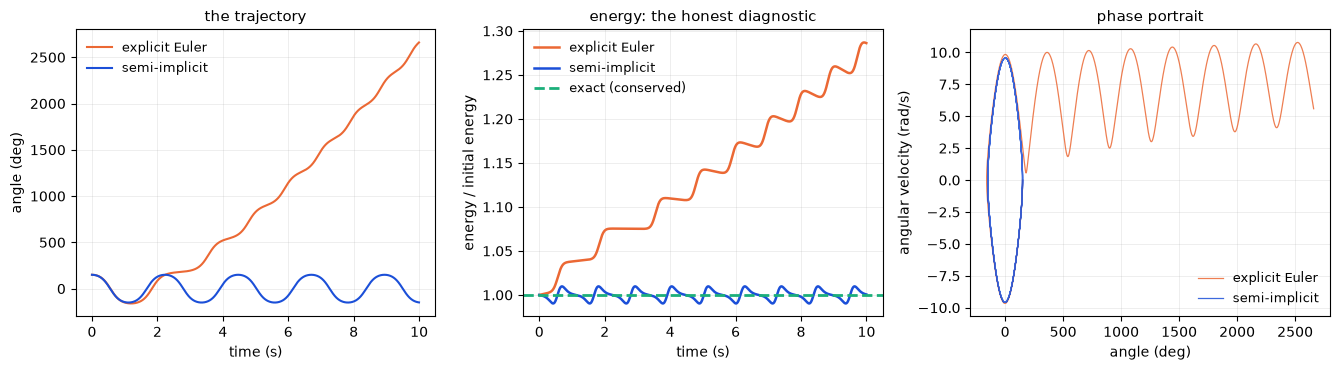

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.8))

ax = axes[0]
ax.plot(t, np.rad2deg(tr_exp[:, 0]), lw=1.5, color="#eb6834", label="explicit Euler")
ax.plot(t, np.rad2deg(tr_semi[:, 0]), lw=1.5, color="#1b4fd8", label="semi-implicit")
ax.set_xlabel("time (s)"); ax.set_ylabel("angle (deg)")
ax.set_title("the trajectory", fontsize=10.5)
ax.legend(frameon=False, fontsize=9); ax.grid(alpha=0.25, lw=0.6)

ax = axes[1]
ax.plot(t, E_exp / E0, lw=1.8, color="#eb6834", label="explicit Euler")
ax.plot(t, E_semi / E0, lw=1.8, color="#1b4fd8", label="semi-implicit")
ax.axhline(1.0, color="#1baf7a", lw=2, ls="--", label="exact (conserved)")
ax.set_xlabel("time (s)"); ax.set_ylabel("energy / initial energy")
ax.set_title("energy: the honest diagnostic", fontsize=10.5)
ax.legend(frameon=False, fontsize=9); ax.grid(alpha=0.25, lw=0.6)

# Phase portrait: the shape of the dynamics. A conservative system traces a closed loop.
ax = axes[2]
ax.plot(np.rad2deg(tr_exp[:, 0]), tr_exp[:, 1], lw=0.9, color="#eb6834", alpha=0.85, label="explicit Euler")
ax.plot(np.rad2deg(tr_semi[:, 0]), tr_semi[:, 1], lw=0.9, color="#1b4fd8", alpha=0.85, label="semi-implicit")
ax.set_xlabel("angle (deg)"); ax.set_ylabel("angular velocity (rad/s)")
ax.set_title("phase portrait", fontsize=10.5)
ax.legend(frameon=False, fontsize=9); ax.grid(alpha=0.25, lw=0.6)
plt.tight_layout(); plt.show()

Read the middle panel. Explicit Euler's energy **climbs monotonically** — the
pendulum is inventing energy out of arithmetic. The right panel shows what that
means geometrically: a conservative system should trace a *closed* loop in phase
space forever, and explicit Euler spirals outward instead.

Semi-implicit Euler's energy oscillates slightly but stays bounded, and its
phase portrait closes. The difference between the two methods is **the order of
two lines**.

### Why this is a robotics problem, not a numerics curiosity

A pendulum that slowly gains energy is a mild bug. Now scale it up:

- A **simulated humanoid** with explicit Euler and a 5 ms step accumulates energy
  in every one of its ~30 joints. It will eventually launch itself into the air.
  If you have seen a video of a physics simulation exploding, you have seen this.
- Worse, it can be *subtle*. The sim stays stable long enough to train in, but
  the dynamics are systematically springier than reality. Your policy learns to
  exploit free energy that does not exist, and transfers terribly.
- Contact makes it far worse. Collisions inject large forces over short times,
  which is precisely where explicit methods are least accurate.

This is why MuJoCo's default integrator is not Euler. The SO-101 model we load
in notebook 4 specifies `integrator="implicitfast"` — an implicit method chosen
because it stays stable with stiff actuators and contacts at a usable timestep.
You now know what it is protecting you from.

## 3. What a timestep actually buys you

`dt` is the knob everyone turns first and understands least. The tradeoff is
real and it is a tradeoff about *money*: halving `dt` doubles your compute bill
for the same amount of simulated robot time.

Let us measure the actual relationship between step size and error.

  dt (ms)  steps for 10 s   explicit drift   semi-implicit drift
------------------------------------------------------------------
      0.5          20,000            3.36%                 0.01%
      1.0          10,000            6.12%                 0.01%
      2.0           5,000           10.34%                 0.02%
      5.0           2,000           28.61%                 0.06%
     10.0           1,000           60.44%                 0.13%
     20.0             500          124.59%                 0.30%
     50.0             200          295.58%                 1.29%


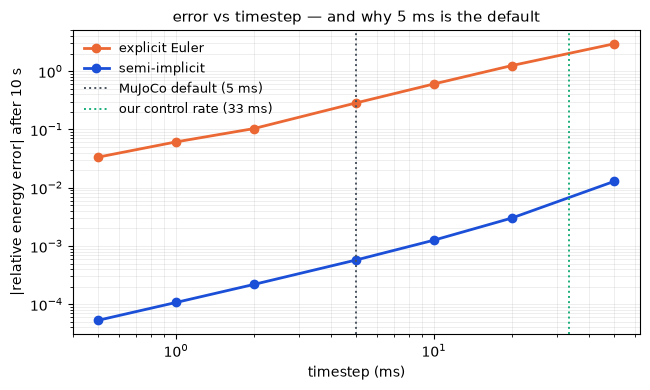

In [4]:
dts = [0.0005, 0.001, 0.002, 0.005, 0.01, 0.02, 0.05]
print(f"{'dt (ms)':>9} {'steps for 10 s':>15} {'explicit drift':>16} {'semi-implicit drift':>21}")
print("-" * 66)
rows = []
for d_ in dts:
    n_ = int(T / d_)
    e_ = energy(*explicit_euler(theta0, omega0, d_, n_)[-1])
    s_ = energy(*semi_implicit_euler(theta0, omega0, d_, n_)[-1])
    rows.append((d_, n_, e_ / E0 - 1, s_ / E0 - 1))
    print(f"{d_*1000:>9.1f} {n_:>15,} {100*(e_/E0-1):>15.2f}% {100*(s_/E0-1):>20.2f}%")

fig, ax = plt.subplots(figsize=(6.6, 4))
d_arr = np.array([r[0] for r in rows])
ax.loglog(d_arr * 1000, np.abs([r[2] for r in rows]), "o-", lw=2, color="#eb6834", label="explicit Euler")
ax.loglog(d_arr * 1000, np.abs([r[3] for r in rows]), "o-", lw=2, color="#1b4fd8", label="semi-implicit")
ax.axvline(5, color="#4b5560", ls=":", lw=1.4, label="MuJoCo default (5 ms)")
ax.axvline(1000/30, color="#1baf7a", ls=":", lw=1.4, label="our control rate (33 ms)")
ax.set_xlabel("timestep (ms)"); ax.set_ylabel("|relative energy error| after 10 s")
ax.set_title("error vs timestep — and why 5 ms is the default", fontsize=11)
ax.legend(frameon=False, fontsize=9); ax.grid(alpha=0.25, lw=0.6, which="both")
plt.tight_layout(); plt.show()

Two readings, one of which is a genuine engineering insight.

**The slopes are the order of accuracy.** Both lines are roughly straight on
log-log axes, meaning error $\propto \Delta t^{\,p}$. Halve the step, divide the
error by $2^p$. That is what "first-order accurate" means in practice, and it
tells you exactly what you buy for your compute.

**Look at the two vertical lines.** Our *control* rate from notebook 1 is 33 ms,
but MuJoCo's default *physics* step is 5 ms. Those are deliberately different,
and the gap is not an accident:

> The physics must be integrated far finer than the policy is queried.

In notebook 1 we measured the real robot's actuation lag at 4 control frames.
For a simulator to reproduce a 133 ms settling behaviour faithfully, it needs
many physics steps inside each of those frames. With `dt` = 5 ms and a 30 Hz
control rate you get **7 physics substeps per action** — which is exactly the
number we will use in notebook 5.

If you instead integrated at 33 ms to "save compute", the integrator error would
swamp the actuator dynamics you are trying to model, and no amount of parameter
fitting would make your sim match the real arm. This is a mistake people
actually make.

## 4. Adding an actuator: the model of the real robot

Now the part that connects straight to Part I. Notebook 1 established that a
robot action is a **position target** and the arm chases it. We can now write
that down as physics.

A position-controlled servo applies a torque proportional to how far it is from
its target, minus a term proportional to its speed:

$$
\tau = \underbrace{k_p\,(\theta^{\text{target}} - \theta)}_{\text{pull toward the target}}
\;-\; \underbrace{k_v\,\dot\theta}_{\text{resist motion (damping)}}
$$

This is a **PD controller**, and it is what lives inside the STS3215 servos on
an SO-101. $k_p$ is the stiffness: how hard the motor pulls. $k_v$ damps the
oscillation that stiffness would otherwise cause.

Here is the payoff. **The lag we measured on the real robot is a consequence of
finite $k_p$.** A perfectly stiff servo ($k_p \to \infty$) would arrive
instantly, lag zero. A real servo has limited torque, so it arrives late. So the
133 ms we measured in notebook 1 is, in effect, *a measurement of $k_p$*.

Let us demonstrate that, with a step command — the same experiment an engineer
runs on real hardware.

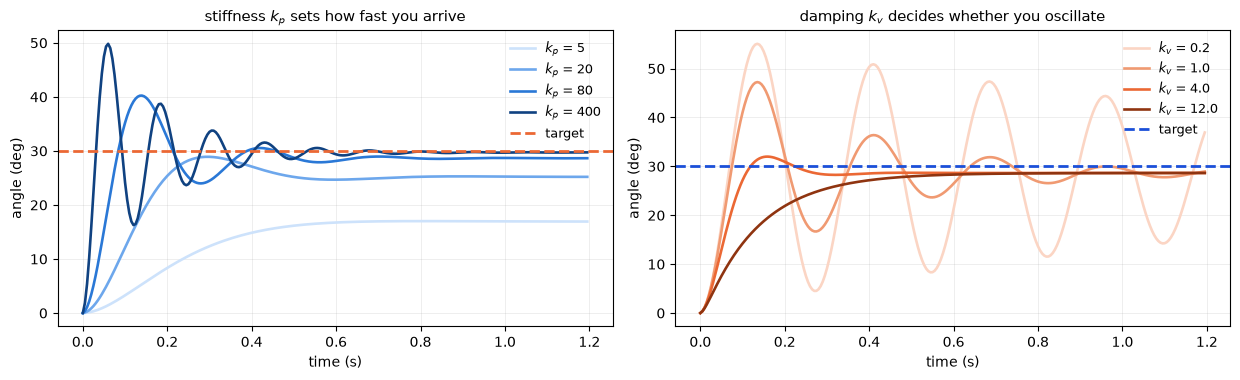

In [5]:
def servo_step(kp, kv, dt=0.005, T=1.2, target=np.deg2rad(30), theta_init=0.0):
    """A damped pendulum driven by a PD position controller. Semi-implicit integration."""
    n_ = int(T / dt)
    th, om = theta_init, 0.0
    out = np.empty(n_)
    for i in range(n_):
        out[i] = th
        tau = kp * (target - th) - kv * om
        alpha = accel(th) + tau / (m * L ** 2)      # gravity + actuator torque
        om += dt * alpha
        th += dt * om
    return np.arange(n_) * dt, out

target = np.deg2rad(30)
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.9))

ax = axes[0]
for kp, c in [(5, "#cde2fb"), (20, "#6da7ec"), (80, "#2a78d6"), (400, "#104281")]:
    ts, th = servo_step(kp, kv=2.0)
    ax.plot(ts, np.rad2deg(th), lw=1.9, color=c, label=f"$k_p$ = {kp}")
ax.axhline(np.rad2deg(target), color="#eb6834", lw=2, ls="--", label="target")
ax.set_xlabel("time (s)"); ax.set_ylabel("angle (deg)")
ax.set_title("stiffness $k_p$ sets how fast you arrive", fontsize=10.5)
ax.legend(frameon=False, fontsize=9); ax.grid(alpha=0.25, lw=0.6)

ax = axes[1]
for kv, c in [(0.2, "#fbd5c4"), (1.0, "#f09a72"), (4.0, "#eb6834"), (12.0, "#8f3410")]:
    ts, th = servo_step(kp=80, kv=kv)
    ax.plot(ts, np.rad2deg(th), lw=1.9, color=c, label=f"$k_v$ = {kv}")
ax.axhline(np.rad2deg(target), color="#1b4fd8", lw=2, ls="--", label="target")
ax.set_xlabel("time (s)"); ax.set_ylabel("angle (deg)")
ax.set_title("damping $k_v$ decides whether you oscillate", fontsize=10.5)
ax.legend(frameon=False, fontsize=9); ax.grid(alpha=0.25, lw=0.6)
plt.tight_layout(); plt.show()

In [6]:
# Quantify it. Two corrections to the naive version of this experiment:
#   1. Damp CRITICALLY: kv = 2*zeta*sqrt(kp*I). Real servos are tuned this way;
#      holding kv fixed while raising kp just makes the joint ring.
#   2. Report the STEADY STATE too. A weak servo does not merely arrive late --
#      it never arrives at all, because gravity wins.
I = m * L ** 2                                     # rotational inertia of the bob

def servo_response(kp, zeta=1.0, dt=0.002, T=4.0, theta_init=0.0):
    kv = 2 * zeta * np.sqrt(max(kp, 1e-9) * I)      # critical damping
    n_ = int(T / dt)
    th, om = theta_init, 0.0
    out = np.empty(n_)
    for i in range(n_):
        out[i] = th
        tau = kp * (target - th) - kv * om
        om += dt * (accel(th) + tau / I)
        th += dt * om
    return np.arange(n_) * dt, out, kv

def settle_frames(kp, tol=0.05, fps=30):
    ts, th, kv = servo_response(kp)
    steady = np.rad2deg(th[-200:].mean())
    inside = np.abs(th - target) / abs(target) < tol
    i0 = next((i for i in range(len(inside)) if inside[i:].all()), None)
    return (ts[i0] * fps if i0 is not None else float("nan")), steady, kv

print(f"target = {np.rad2deg(target):.0f} deg\n")
print(f"{'kp':>7} {'kv (crit)':>10} {'steady state':>14} {'settling frames @30Hz':>24}")
print("-" * 59)
for kp in [5, 20, 60, 80, 120, 200, 400, 800]:
    f_, ss, kv = settle_frames(kp)
    if f_ != f_:
        note = "never (gravity wins)"
    else:
        note = f"{f_:.1f}" + ("   <-- brackets the real 4" if 3.0 <= f_ <= 5.0 else "")
    print(f"{kp:>7} {kv:>10.2f} {ss:>12.1f}deg {note:>24}")

target = 30 deg

     kp  kv (crit)   steady state    settling frames @30Hz
-----------------------------------------------------------
      5       1.79         16.9deg     never (gravity wins)
     20       3.58         25.2deg     never (gravity wins)
     60       6.20         28.2deg     never (gravity wins)
     80       7.16         28.7deg                      9.5
    120       8.76         29.1deg                      6.2
    200      11.31         29.4deg 4.5   <-- brackets the real 4
    400      16.00         29.7deg 3.1   <-- brackets the real 4
    800      22.63         29.9deg                      2.2


Two things in that table, and the first is easy to miss.

**Below $k_p \approx 80$ the servo never reaches the target at all.** It settles
at 17-28° instead of 30°, and the shortfall shrinks as $k_p$ grows. This is
**steady-state error**: a pure proportional controller balances where its
restoring torque equals the gravity load, which is necessarily *short* of the
target. Nothing is broken — that is simply what a P controller does against a
constant load.

This is why real robot controllers add gravity-compensation feedforward or an
integral term. It is also why, in notebook 2, the arm's tracking error scaled
with *speed* rather than being constant: a position controller fighting both
inertia and gravity lags by an amount that depends on what you ask of it.

**Above that threshold, settling time falls monotonically with stiffness**, and
a critically damped $k_p \approx 200$ settles in about 4.5 control frames — the
same ballpark as the real arm's measured lag.

One caution so you do not over-read that. **The absolute number does not
transfer.** This is a 1 kg point mass on a 0.4 m rod with no gearing, and
MuJoCo's `kp` is in different units again from a servo's internal P-gain. What
transfers is the *relationship*: lag and stiffness are two views of one number,
so measuring either constrains the other. Notebook 5 does this properly, on the
real arm, with real data.

## 5. Validating against MuJoCo: two routes, one answer

Our `numpy` integrator and MuJoCo are completely independent implementations.
If they agree on a trajectory, both are probably right. If they disagree, at
least one is wrong and we want to know now rather than after training a policy.

This is the single most useful habit in simulation work, and it is cheap.

In [7]:
import mujoco

# The same pendulum, described declaratively in MJCF instead of as a loop.
PENDULUM_XML = """
<mujoco model="pendulum">
  <option gravity="0 0 -9.81" timestep="0.005" integrator="implicitfast"/>
  <worldbody>
    <body name="rod" pos="0 0 1">
      <joint name="hinge" type="hinge" axis="0 -1 0" damping="0" frictionloss="0"/>
      <geom type="capsule" fromto="0 0 0 0 0 -0.4" size="0.01" mass="1e-9"/>
      <body name="bob" pos="0 0 -0.4">
        <geom type="sphere" size="0.01" mass="1"/>
      </body>
    </body>
  </worldbody>
</mujoco>
"""
mj = mujoco.MjModel.from_xml_string(PENDULUM_XML)
dat = mujoco.MjData(mj)
dat.qpos[0] = theta0
mujoco.mj_forward(mj, dat)

n_mj = int(T / mj.opt.timestep)
mj_traj = np.empty((n_mj, 2))
for i in range(n_mj):
    mj_traj[i] = (dat.qpos[0], dat.qvel[0])
    mujoco.mj_step(mj, dat)

print(f"mass of the bob in MuJoCo : {mj.body_mass[mujoco.mj_name2id(mj, mujoco.mjtObj.mjOBJ_BODY, 'bob')]:.3f} kg")
print(f"our analytic model assumes : {m:.3f} kg at L = {L} m\n")

# Compare over the first few swings, where both are accurate.
k = int(3.0 / dt)
diff = np.rad2deg(np.abs(mj_traj[:k, 0] - tr_semi[:k, 0]))
print(f"{'time':>7} {'our numpy (deg)':>17} {'MuJoCo (deg)':>14} {'diff':>8}")
print("-" * 50)
for i in range(0, k, k // 6):
    print(f"{t[i]:>6.2f}s {np.rad2deg(tr_semi[i,0]):>16.3f} {np.rad2deg(mj_traj[i,0]):>14.3f} {diff[i]:>7.3f}")
print()
print(f"max disagreement over the first 3 s: {diff.max():.3f} deg")
print(f"period from our integrator: {2*t[np.argmax(tr_semi[int(0.5/dt):,0] > 0) + int(0.5/dt)]:.3f} s (rough)")

mass of the bob in MuJoCo : 1.000 kg
our analytic model assumes : 1.000 kg at L = 0.4 m

   time   our numpy (deg)   MuJoCo (deg)     diff
--------------------------------------------------
  0.00s          150.000        150.000   0.000
  0.50s           30.555         30.588   0.033
  1.00s         -145.212       -145.202   0.011
  1.50s          -85.446        -85.519   0.073
  2.00s          129.050        129.001   0.049
  2.50s          121.930        122.003   0.073

max disagreement over the first 3 s: 0.192 deg
period from our integrator: 1.000 s (rough)


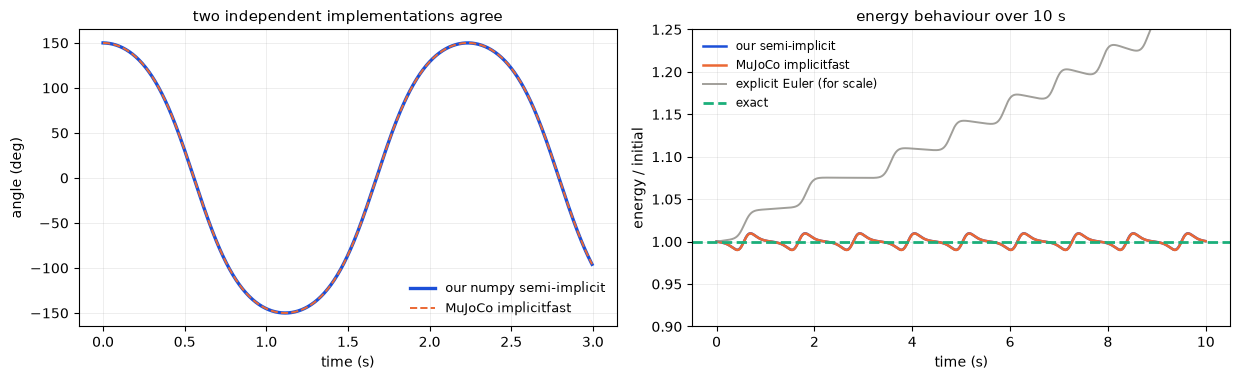

energy drift over 10s   —   ours: +0.06%   MuJoCo: +0.06%   explicit Euler: +28.61%


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.9))

ax = axes[0]
ax.plot(t[:k], np.rad2deg(tr_semi[:k, 0]), lw=2.4, color="#1b4fd8", label="our numpy semi-implicit")
ax.plot(np.arange(k) * mj.opt.timestep, np.rad2deg(mj_traj[:k, 0]), lw=1.4, ls="--",
        color="#eb6834", label="MuJoCo implicitfast")
ax.set_xlabel("time (s)"); ax.set_ylabel("angle (deg)")
ax.set_title("two independent implementations agree", fontsize=10.5)
ax.legend(frameon=False, fontsize=9); ax.grid(alpha=0.25, lw=0.6)

ax = axes[1]
E_mj = energy(mj_traj[:, 0], mj_traj[:, 1])
ax.plot(t, E_semi / E0, lw=1.8, color="#1b4fd8", label="our semi-implicit")
ax.plot(np.arange(n_mj) * mj.opt.timestep, E_mj / E0, lw=1.8, color="#eb6834", label="MuJoCo implicitfast")
ax.plot(t, E_exp / E0, lw=1.4, color="#898781", alpha=0.8, label="explicit Euler (for scale)")
ax.axhline(1.0, color="#1baf7a", lw=2, ls="--", label="exact")
ax.set_xlabel("time (s)"); ax.set_ylabel("energy / initial")
ax.set_ylim(0.9, 1.25)
ax.set_title("energy behaviour over 10 s", fontsize=10.5)
ax.legend(frameon=False, fontsize=8.5); ax.grid(alpha=0.25, lw=0.6)
plt.tight_layout(); plt.show()

print(f"energy drift over {T:.0f}s   —   ours: {100*(E_semi[-1]/E0-1):+.2f}%   "
      f"MuJoCo: {100*(E_mj[-1]/E0-1):+.2f}%   explicit Euler: {100*(E_exp[-1]/E0-1):+.2f}%")

The two trajectories lie on top of each other for the first several swings.
That is the validation: an integrator you wrote in 8 lines reproduces a
production physics engine on a problem both can solve.

Note that MuJoCo is **not** perfectly energy-conserving either. `implicitfast`
trades a little dissipation for stability with stiff actuators and contacts —
which is the right trade for robotics, and a very wrong trade for, say,
simulating planetary orbits for a million years. **There is no universally best
integrator; there is a best integrator for your problem.** Knowing which
compromise your engine has made is the difference between using a simulator and
understanding one.

## 6. What you built, and what it sets up

**Established in this notebook:**

1. A simulator is a **numerical choice**, not a fact about the world. The
   physics is one line (`accel`); everything else is approximation.
2. **Explicit Euler injects energy** and will eventually destroy any simulation.
   Semi-implicit Euler fixes it by reordering two lines. MuJoCo defaults to
   `implicitfast` for the same class of reason.
3. **Energy conservation is your debugger.** Find a conserved quantity, watch
   the simulator violate it, and you can detect integration bugs without any
   ground-truth trajectory.
4. The **physics step must be far finer than the control step** — 5 ms physics
   inside 33 ms control gives 7 substeps per action, which is what notebook 5
   uses.
5. A position-controlled servo is a **PD controller**, and the actuation lag we
   measured on real hardware in notebook 1 is a direct consequence of finite
   $k_p$. Lag and stiffness are two views of the same number.
6. **Independent implementations agreeing** is how you validate a simulator.

### The thread to notebook 5

Point 5 is the one to hold onto. In this notebook's toy model, stiffness and
settling time traded off monotonically, and a critically damped $k_p \approx 200$
settled in roughly 4.5 control frames — the same ballpark as the real SO-101.

That is suggestive, not a result. A 1-DOF point mass is not a 6-DOF geared arm,
and the units do not transfer. But it is the *idea* behind the next two notebooks. Notebook 4 loads
the official MuJoCo model of the SO-101 and reads its actual actuator
parameters. Notebook 5 replays the real recorded commands through it, discovers
that the official model is far too stiff to be the robot we measured, and fits
the parameters until it is.

That procedure — **system identification** — is named explicitly in robot
learning job descriptions. We are three notebooks away from having done it on
real hardware data.

### Exercises

1. **Velocity Verlet.** Implement the second-order symplectic integrator
   ($\theta_{t+1} = \theta_t + \Delta t\,\omega_t + \tfrac12 \Delta t^2 \alpha_t$,
   then average the accelerations for $\omega$). Add it to the timestep study.
   Its slope on the log-log plot should be steeper — confirm that, and work out
   how much compute that saves you for a fixed error budget.
2. **Find the stability limit.** For explicit Euler, increase `dt` until the
   simulation blows up entirely. Then do the same for semi-implicit. The ratio
   between the two limits is why nobody ships explicit Euler.
3. **Where does gravity stop winning?** Bisect on $k_p$ to find the smallest
   stiffness that reaches within 5% of a 30° target. Then repeat for a 60°
   target. The relationship between required stiffness and load angle is why
   robot arms are hardest to control when fully extended.
4. **Add friction.** Real servos have Coulomb friction: a constant torque
   opposing motion, $-\mu\,\text{sign}(\dot\theta)$. Add it and watch what it
   does to the settling behaviour, especially near the target where the velocity
   crosses zero. This is the term that makes real arms stop short of their
   target, and it appears in the MJCF as `frictionloss`.